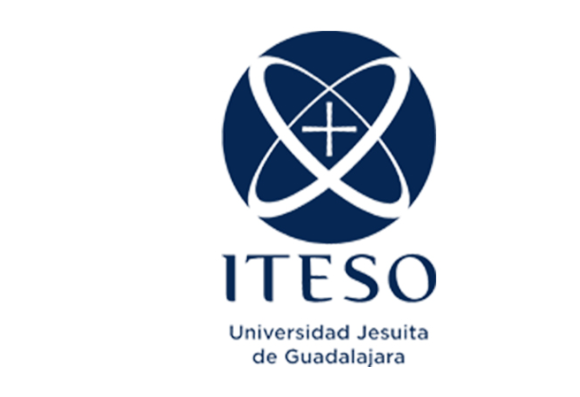

# Tarea 4. Reporte de práctica de red neuronal ADALINE para regresión.

**Integrantes:**

- Valeria Esmer Lobo

- Dayanni Godoy Rosales

- Estephany Lisset Herrera Placencia

- Maria Fernanda Vargas Vaca

**Fecha:**
16 de Octubre de 2026 

**Institución:**
Instituto Tecnológico y de Estudios Superiores de Occidente

**Materia:** Métodos de Inteligencia Artificial

## Desarrollo

### Definición del problema
El problema a resolver consiste en la **predicción de series temporales financieras**, específicamente el precio de cierre de un activo en el mercado de valores (en este caso, acciones de Google), utilizando un enfoque basado en **rezagos temporales (lags)**. 

En los mercados financieros, se asume que el comportamiento histórico reciente de un activo contiene información valiosa sobre su tendencia a corto plazo. Por lo tanto, el problema se modela matemáticamente tomando el precio de un día específico como la variable dependiente (etiqueta a predecir) y los precios de los $N$ días anteriores como las variables independientes (características o rezagos). De esta manera, transformamos una secuencia lineal de tiempo en un problema de aprendizaje supervisado de regresión, donde un modelo lineal (como la red ADALINE) buscará encontrar los pesos óptimos que relacionen los precios pasados con el precio futuro, permitiendo así pronosticar el valor del activo en el día de mañana.

### Descripción del algoritmo

La **Red Neuronal ADALINE (ADAptive LInear NEuron)** es un algoritmo de aprendizaje automático supervisado, desarrollado inicialmente para tareas de clasificación binaria, pero que, gracias a su arquitectura, es ampliamente utilizado para problemas de **regresión lineal**. 

A diferencia del Perceptrón clásico, que actualiza sus pesos basándose en una función de activación escalón (salida binaria), ADALINE utiliza una **función de activación lineal**. Esto significa que la salida de la red es una combinación lineal directa de las entradas y sus respectivos pesos sinápticos ($Y = X \cdot W$). 

Para el proceso de aprendizaje, ADALINE emplea el **descenso de gradiente** a través de la **Regla de Widrow-Hoff** (también conocida como regla delta). El objetivo de esta regla es minimizar una función de costo, típicamente el Error Cuadrático Medio (MSE), calculando la diferencia continua entre la salida real y la salida lineal estimada por la red, antes de pasar por cualquier cuantificador. Al ajustar los pesos en dirección contraria al gradiente del error, el modelo converge hacia los pesos óptimos. 

*Nota sobre la implementación:* Aunque el algoritmo ADALINE estándar encuentra los pesos de forma iterativa, el problema subyacente que resuelve es de naturaleza lineal. Por ello, matemáticamente es equivalente a resolver el sistema utilizando la ecuación normal de **Mínimos Cuadrados** ($W = (X^T X)^{-1} X^T Y$), método analítico directo que se refleja en nuestro script de implementación para encontrar los pesos óptimos en un solo paso.

### Pseudocódigo de ADALINE 

El proceso iterativo del algoritmo ADALINE consta de los siguientes 6 pasos fundamentales:

INICIO
    Descargar historial de precios del activo en el rango de fechas definido
    Extraer y almacenar los precios de cierre en el vector 'precios'
    Definir el número de rezagos nrez = 10
    Inicializar lista X vacía

    PARA k = 0 HASTA nrez HACER
        Extraer subconjunto de 'precios' desplazado k posiciones
        Agregar el subconjunto como columna a X
    FIN PARA

    Definir vector de etiquetas Y como la primera columna de X (precio actual)
    Construir matriz Xa uniendo una columna de unos (sesgo) y las columnas restantes de X (rezagos)
    
    Calcular ntrain como el 70% de la cantidad total de datos
    Separar Xa y Y en conjuntos de entrenamiento (Train) y prueba (Test) usando ntrain

    Calcular pesos Wmc mediante mínimos cuadrados: Wmc = (Xa_trainᵀ * Xa_train)⁻¹ * Xa_trainᵀ * Y_train
    Calcular salida estimada de entrenamiento Yg_mc = Xa_train * Wmc
    Calcular salida estimada de prueba Yg_rec = Xa_test * Wmc

    Inicializar vector 'last' con un 1 en la primera posición
    Asignar a 'last' los últimos 'nrez' precios invertidos en las posiciones restantes
    Calcular predicción del día de mañana = last * Wmc

    Mostrar en consola el último precio real y la predicción del día de mañana
    Graficar los precios reales originales
    Graficar la estimación del modelo en entrenamiento y en prueba
    Graficar el punto de la predicción del día de mañana
FIN

Este es el código para esta tarea:

In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def download_values(ticker, start_date, end_date, interval='d', data_type='history'):
    # Mapear los intervalos cortos al formato requerido por yfinance
    interval_map = {
        'd': '1d',  # Diario
        'w': '1wk', # Semanal
        'm': '1mo'  # Mensual
    }
    yf_interval = interval_map.get(interval.lower(), '1d')
    
    # Inicializar el objeto Ticker
    stock = yf.Ticker(ticker)
    
    if data_type.lower() == 'history':
        # Descargar el historial de precios
        data = stock.history(
            start=start_date, 
            end=end_date, 
            interval=yf_interval
        )
        
        # Eliminar columnas de zona horaria si es necesario (opcional)
        if not data.empty:
            data.index = data.index.tz_localize(None)
            
        return data
        
    elif data_type.lower() == 'dividends':
        # Retornar solo dividendos en ese rango de fechas
        dividends = stock.dividends
        if not dividends.empty:
            dividends.index = dividends.index.tz_localize(None)
            return dividends.loc[start_date:end_date]
        return dividends
        
    else:
        raise ValueError("El data_type debe ser 'history' o 'dividends'.")

# Ejecución solicitada
res = download_values('GOOG', '2020-10-06', '2023-10-06', 'd', 'history')

# Mostrar las primeras filas del resultado
print("Datos descargados:")
print(res.head())

# Almacenar los datos
precios = res["Close"].to_numpy()

# Número de rezagos en el tiempo
nrez = 50

X = []

for k in range(nrez + 1):
    X.append(precios[nrez - k: len(precios) - k])

X = np.column_stack(X)
m_filas = X.shape[0]

# Datos de entrenamiento Y y etiqueta Xa = x asterisco [1,x1,x2]
Y = X[:,0].reshape(-1,1)
Xa = np.column_stack((np.ones(m_filas), X[:,1:]))

# Partición de los datos de entrenamiento (70% Train y 30% Test)
ntrain = int(np.round(0.7 * Xa.shape[0]))

Xa_train = Xa[:ntrain, :]
Xa_test = Xa[ntrain:,:]
Y_train = Y[:ntrain,:]
Y_test = Y[ntrain:,:]

# Mínimos cuadrados
Wmc = np.linalg.inv(Xa_train.T @ Xa_train) @ Xa_train.T @ Y_train

# Y estimada
Yg_mc = Xa_train @ Wmc
Yg_rec = Xa_test @ Wmc

# ==========================================
# PREDICCIÓN PARA M DÍAS (NUEVO BLOQUE)
# ==========================================
m_dias = 10 # <--- Define aquí cuántos días al futuro quieres predecir
predicciones_futuras = []

# Tomamos los últimos 'nrez' precios reales y los invertimos para el formato de rezago
current_lags = precios[-nrez:][::-1]

for i in range(m_dias):
    # Preparar el vector de entrada con el 1 inicial (bias/sesgo)
    last = np.zeros((1, nrez + 1))
    last[0, 0] = 1
    last[0, 1:] = current_lags
    
    # Predecir el siguiente día
    new_price = last @ Wmc
    prediccion_actual = new_price[0, 0]
    predicciones_futuras.append(prediccion_actual)
    
    # Actualizar los rezagos para la siguiente iteración:
    # Insertamos la nueva predicción al inicio y eliminamos el último valor
    current_lags = np.insert(current_lags, 0, prediccion_actual)[:-1]

print(f"\nPrecio actual (último día real): {Y[-1,0]:.4f}")
print(f"Predicciones para los próximos {m_dias} días:")
for i, p in enumerate(predicciones_futuras):
    print(f"  Día {i+1}: {p:.4f}")

# ==========================================
# GRÁFICA ACTUALIZADA
# ==========================================
plt.figure(figsize=(12, 6))

# Graficar datos reales e históricos ajustados
plt.plot(range(len(Y)), Y, "b-", linewidth=2, label="Precios Reales")
plt.plot(range(len(Yg_mc)), Yg_mc, "r", linewidth=2, label="Entrenamiento (Train)")
plt.plot(range(ntrain, ntrain + len(Yg_rec)), Yg_rec, "g", linewidth=2, label="Prueba (Test)")

# Graficar la curva de predicción de m días hacia el futuro
rango_futuro = range(len(Y), len(Y) + m_dias)
plt.plot(rango_futuro, predicciones_futuras, "m*-", markersize=10, linewidth=2, label=f"Predicción ({m_dias} días)")

plt.grid(True)
plt.legend(loc="best", fontsize=12)
plt.title(f"Modelo AR({nrez}) - Predicción a {m_dias} días para GOOG")
plt.tight_layout()
plt.show()

## Parte 3

Datos descargados:
                 Open       High        Low      Close    Volume  Dividends  \
Date                                                                          
2020-10-06  73.086743  73.640496  71.749903  71.990128  24908000        0.0   
2020-10-07  72.527550  72.758857  71.126325  72.329430  34924000        0.0   
2020-10-08  72.567165  73.800978  72.567165  73.599388  23756000        0.0   
2020-10-09  74.033781  75.114541  73.773747  75.050156  28706000        0.0   
2020-10-12  76.426124  78.945263  75.909518  77.721352  49652000        0.0   

            Stock Splits  
Date                      
2020-10-06           0.0  
2020-10-07           0.0  
2020-10-08           0.0  
2020-10-09           0.0  
2020-10-12           0.0  
Total de datos: 755

Último precio real: 134.71
 Rezagos  RMSE train  RMSE test  MAE test  R2 train  R2 test  Pred. día 1  Pred. día 10
       5       2.251      2.110     1.604    0.9868   0.9823       134.74        133.60
      10      

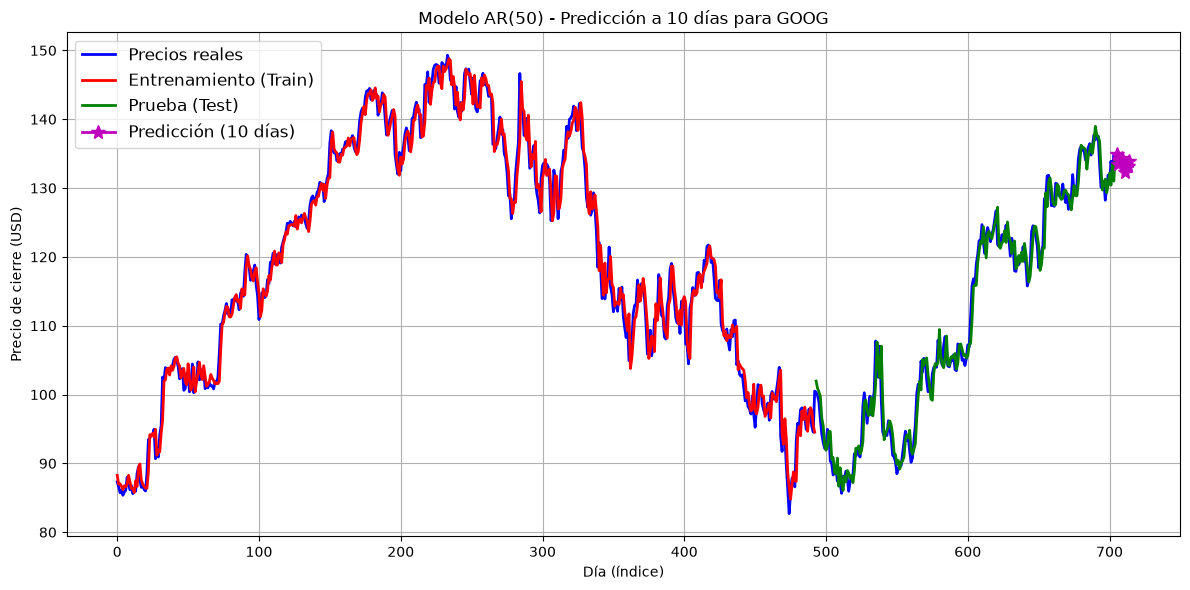

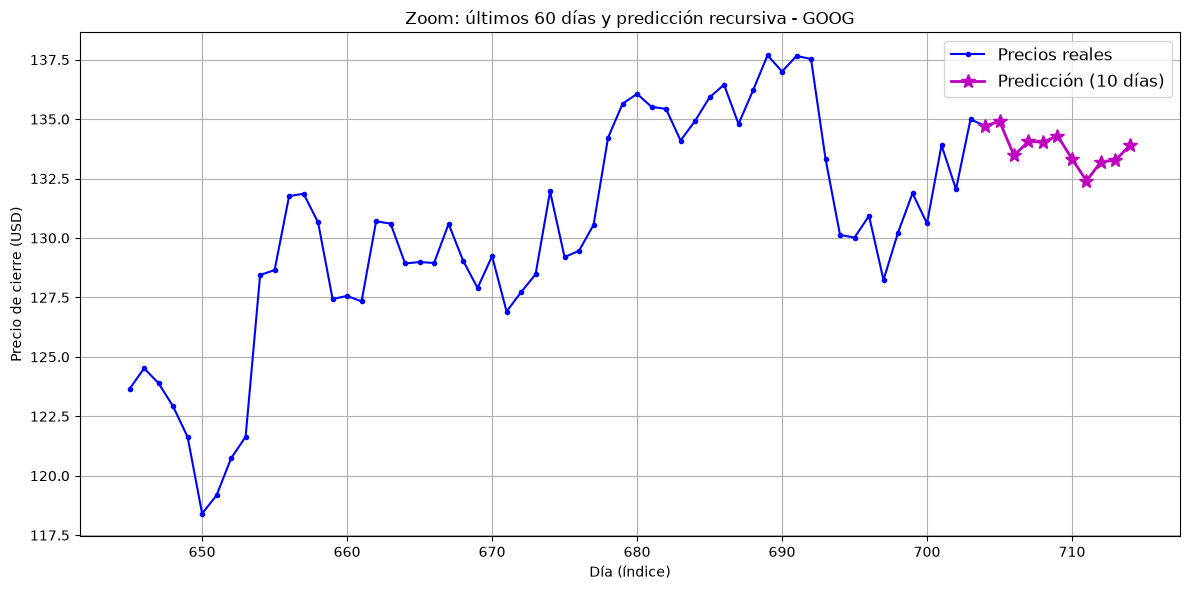

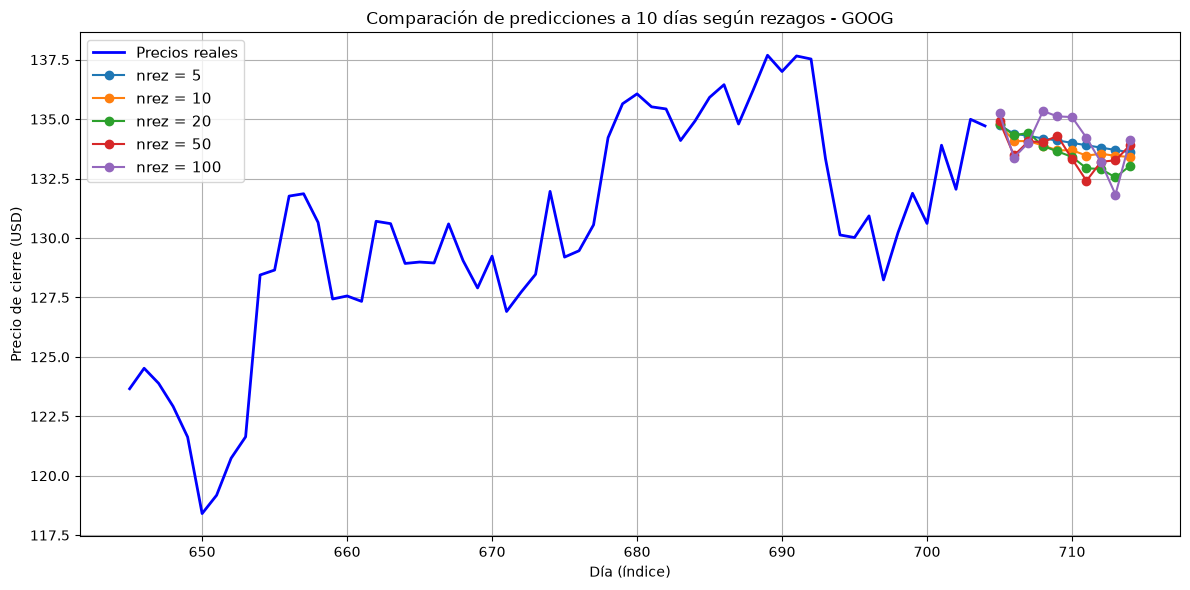

In [3]:
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ======================================================================
# 1. DESCARGA DE DATOS
# ======================================================================
def download_values(ticker, start_date, end_date, interval='d', data_type='history'):
    """Descarga el historial de precios (o dividendos) de un activo con yfinance."""
    interval_map = {'d': '1d', 'w': '1wk', 'm': '1mo'}
    yf_interval = interval_map.get(interval.lower(), '1d')

    stock = yf.Ticker(ticker)

    if data_type.lower() == 'history':
        data = stock.history(start=start_date, end=end_date, interval=yf_interval)
        if not data.empty:
            data.index = data.index.tz_localize(None)  # quitar zona horaria
        return data

    elif data_type.lower() == 'dividends':
        dividends = stock.dividends
        if not dividends.empty:
            dividends.index = dividends.index.tz_localize(None)
            return dividends.loc[start_date:end_date]
        return dividends

    raise ValueError("data_type debe ser 'history' o 'dividends'.")


# ======================================================================
# 2. CONSTRUCCIÓN DE LA MATRIZ DE REZAGOS
# ======================================================================
def build_lag_matrix(precios, nrez):
    """
    Construye Y (precio actual) y Xa = [1, x(t-1), ..., x(t-nrez)].
    Columna 0 de X = precio en t; columnas 1..nrez = rezagos.
    """
    X = np.column_stack([precios[nrez - k: len(precios) - k] for k in range(nrez + 1)])
    Y = X[:, 0].reshape(-1, 1)                           # etiqueta
    Xa = np.column_stack((np.ones(X.shape[0]), X[:, 1:]))  # sesgo + rezagos
    return Xa, Y


# ======================================================================
# 3. ENTRENAMIENTO (MÍNIMOS CUADRADOS) Y MÉTRICAS
# ======================================================================
def train_model(Xa, Y, train_ratio=0.7):
    """Separa en train/test (70/30, sin mezclar por ser serie de tiempo) y calcula pesos."""
    ntrain = int(np.round(train_ratio * Xa.shape[0]))
    Xa_train, Xa_test = Xa[:ntrain], Xa[ntrain:]
    Y_train, Y_test = Y[:ntrain], Y[ntrain:]

    # Ecuación normal: W = (X'X)^-1 X'Y  (pinv es más estable numéricamente que inv)
    Wmc = np.linalg.pinv(Xa_train.T @ Xa_train) @ Xa_train.T @ Y_train

    Yg_train = Xa_train @ Wmc
    Yg_test = Xa_test @ Wmc
    return Wmc, ntrain, Yg_train, Yg_test, Y_train, Y_test


def metrics(y_real, y_est):
    """Devuelve RMSE, MAE y R^2."""
    err = y_real - y_est
    rmse = np.sqrt(np.mean(err ** 2))
    mae = np.mean(np.abs(err))
    r2 = 1 - np.sum(err ** 2) / np.sum((y_real - y_real.mean()) ** 2)
    return rmse, mae, r2


# ======================================================================
# 4. PREDICCIÓN RECURSIVA A N DÍAS (MODIFICACIÓN PRINCIPAL)
# ======================================================================
def predict_n_days(precios, Wmc, nrez, n_dias):
    """
    Predice n_dias hacia el futuro usando las propias predicciones de la red.
    En cada paso:
      1) Se arma el vector [1, p(t), p(t-1), ..., p(t-nrez+1)].
      2) Se predice p(t+1) = vector @ W.
      3) La predicción se inserta al inicio de los rezagos y se descarta
         el rezago más antiguo (ventana deslizante).
    """
    predicciones = []
    lags = precios[-nrez:][::-1].copy()  # más reciente primero

    for _ in range(n_dias):
        entrada = np.concatenate(([1.0], lags)).reshape(1, -1)
        nuevo = (entrada @ Wmc).item()
        predicciones.append(nuevo)
        lags = np.insert(lags, 0, nuevo)[:-1]  # realimentación

    return np.array(predicciones)


# ======================================================================
# 5. PROGRAMA PRINCIPAL
# ======================================================================
if __name__ == "__main__":
    TICKER = 'GOOG'
    N_DIAS = 10            # días futuros a predecir
    NREZ_PRINCIPAL = 50    # rezagos del caso principal
    NREZ_PRUEBAS = [5, 10, 20, 50, 100]  # casos de prueba para la tabla

    res = download_values(TICKER, '2020-10-06', '2023-10-06', 'd', 'history')
    print("Datos descargados:")
    print(res.head())
    precios = res["Close"].to_numpy()
    print(f"Total de datos: {len(precios)}\n")

    # ---------- Tabla de casos de prueba con distintos rezagos ----------
    filas = []
    for nrez in NREZ_PRUEBAS:
        Xa, Y = build_lag_matrix(precios, nrez)
        W, nt, Yg_tr, Yg_te, Y_tr, Y_te = train_model(Xa, Y)
        rmse_tr, _, r2_tr = metrics(Y_tr, Yg_tr)
        rmse_te, mae_te, r2_te = metrics(Y_te, Yg_te)
        futuro = predict_n_days(precios, W, nrez, N_DIAS)
        filas.append({
            "Rezagos": nrez,
            "RMSE train": round(rmse_tr, 3),
            "RMSE test": round(rmse_te, 3),
            "MAE test": round(mae_te, 3),
            "R2 train": round(r2_tr, 4),
            "R2 test": round(r2_te, 4),
            "Pred. día 1": round(futuro[0], 2),
            f"Pred. día {N_DIAS}": round(futuro[-1], 2),
        })

    tabla = pd.DataFrame(filas)
    print(f"Último precio real: {precios[-1]:.2f}")
    print(tabla.to_string(index=False))

    # ---------- Caso principal ----------
    nrez = NREZ_PRINCIPAL
    Xa, Y = build_lag_matrix(precios, nrez)
    Wmc, ntrain, Yg_mc, Yg_rec, Y_train, Y_test = train_model(Xa, Y)
    futuras = predict_n_days(precios, Wmc, nrez, N_DIAS)

    print(f"\nPredicciones a {N_DIAS} días (nrez={nrez}):")
    for i, p in enumerate(futuras, 1):
        print(f"  Día {i}: {p:.4f}")

    # ---------- Gráfica 1: ajuste completo + predicción ----------
    plt.figure(figsize=(12, 6))
    plt.plot(range(len(Y)), Y, "b-", linewidth=2, label="Precios reales")
    plt.plot(range(ntrain), Yg_mc, "r", linewidth=2, label="Entrenamiento (Train)")
    plt.plot(range(ntrain, ntrain + len(Yg_rec)), Yg_rec, "g", linewidth=2, label="Prueba (Test)")
    plt.plot(range(len(Y), len(Y) + N_DIAS), futuras, "m*-", markersize=10,
             linewidth=2, label=f"Predicción ({N_DIAS} días)")
    plt.grid(True)
    plt.legend(loc="best", fontsize=12)
    plt.xlabel("Día (índice)")
    plt.ylabel("Precio de cierre (USD)")
    plt.title(f"Modelo AR({nrez}) - Predicción a {N_DIAS} días para {TICKER}")
    plt.tight_layout()
    plt.show()

    # ---------- Gráfica 2: zoom a los últimos 60 días + predicción ----------
    ventana = 60
    plt.figure(figsize=(12, 6))
    plt.plot(range(len(Y) - ventana, len(Y)), Y[-ventana:], "b-o", markersize=3, label="Precios reales")
    plt.plot(range(len(Y) - 1, len(Y) + N_DIAS),
             np.concatenate(([Y[-1, 0]], futuras)), "m*-", markersize=10,
             linewidth=2, label=f"Predicción ({N_DIAS} días)")
    plt.grid(True)
    plt.legend(loc="best", fontsize=12)
    plt.xlabel("Día (índice)")
    plt.ylabel("Precio de cierre (USD)")
    plt.title(f"Zoom: últimos {ventana} días y predicción recursiva - {TICKER}")
    plt.tight_layout()
    plt.show()

    # ---------- Gráfica 3: predicción recursiva según número de rezagos ----------
    plt.figure(figsize=(12, 6))
    plt.plot(range(len(Y) - ventana, len(Y)), Y[-ventana:], "b-", linewidth=2, label="Precios reales")
    for n in NREZ_PRUEBAS:
        Xa_n, Y_n = build_lag_matrix(precios, n)
        W_n = train_model(Xa_n, Y_n)[0]
        f_n = predict_n_days(precios, W_n, n, N_DIAS)
        plt.plot(range(len(Y), len(Y) + N_DIAS), f_n, "o-", label=f"nrez = {n}")
    plt.grid(True)
    plt.legend(loc="best", fontsize=11)
    plt.xlabel("Día (índice)")
    plt.ylabel("Precio de cierre (USD)")
    plt.title(f"Comparación de predicciones a {N_DIAS} días según rezagos - {TICKER}")
    plt.tight_layout()
    plt.show()

### Observaciones

1. Con pocos rezagos es suficiente. Con 5, 10, 20 y 50 rezagos los resultados son casi iguales, con un RMSE de aproximadamente 2.1 USD. Por eso, usar más datos históricos no necesariamente mejora la predicción.

2. Con 100 rezagos empeora el resultado. El error de prueba sube a 2.48 USD, aunque el error de entrenamiento baja. Esto puede indicar sobreajuste, porque el modelo se ajusta mejor a los datos que ya conoce, pero pierde precisión con datos nuevos.

3. El ajuste parece bueno, pero tiene sus límites. El \(R^2\) de aproximadamente 0.98 indica un buen ajuste, aunque también se debe a que los precios de días consecutivos suelen ser parecidos. Esto no significa que el modelo pueda predecir correctamente todos los movimientos del mercado.

4. Predicción a 10 días. Las predicciones empiezan cerca del último precio real, de 134.71 USD, y terminan entre 133.04 y 134.10 USD. El modelo muestra una ligera baja, pero no logra anticipar los cambios bruscos del precio.

5. Más rezagos generan mayor variación. Con 100 rezagos, las predicciones presentan más movimientos que con 5 o 10. Esto refuerza la posibilidad de que el modelo esté sobreajustado.

6. Limitación del modelo. La predicción depende de los precios anteriores y, al utilizar sus propias estimaciones, los errores pueden acumularse. Por eso, los resultados a 10 días son menos confiables.

### Conclusion 

Con esta práctica entendí cómo utilizar los precios históricos para predecir una acción mediante rezagos. Me llamó la atención que usar entre 5 y 50 rezagos diera resultados muy parecidos, mientras que con 100 aumentara el error de prueba. También aprendí que, aunque el modelo tenga un buen ajuste, eso no significa que pueda anticipar los movimientos reales del mercado. La parte más interesante fue la predicción a 10 días, porque cada estimación se utiliza para calcular la siguiente y los errores pueden acumularse. En general, considero que ADALINE es útil para aprender cómo funcionan estos modelos, pero sus resultados deben tomarse con cuidado y no utilizarse por sí solos para tomar decisiones de inversión.